# O pipeline do paper, etapa por etapa

Este notebook roda, em ordem, todas as etapas que produzem os números do paper *Editing and Spec Decay in Spec-Driven
Development*. Rode as células de cima para baixo. A execução leva cerca de 8 minutos.

- **Entradas:** o SpecMine v1.0 (ZIP do Zenodo) e a coleta congelada da API do GitHub (diffs dos PRs), os rótulos humanos e as
  decisões que estão em `data/`. Nenhuma etapa baixa nada, chama LLM ou altera uma entrada.
- **Saídas:** as mesmas de `bash scripts/reproduzir.sh` (`data/derived/`, `docs/key_numbers_final.json`,
  `data/validation/resultado_*.csv`). Antes de começar, o notebook tira a impressão digital das saídas que já existem;
  no fim, confere que a nova execução reproduziu exatamente as mesmas.
- **Diferença para o `reproduzir.sh`:** aqui o pipeline roda uma vez e mostra a saída de cada etapa. O teste de
  determinismo (rodar duas vezes e comparar) fica no `reproduzir.sh`.

Cada etapa é um script de `scripts/`, executado num processo separado com `python -I`, como no `reproduzir.sh`.

In [1]:
import hashlib, os, subprocess, sys, time
import pandas as pd
from IPython.display import Image, display

ROOT = os.path.abspath(".")
PY = os.path.join(ROOT, ".venv", "bin", "python")
PY = PY if os.path.exists(PY) else sys.executable
REPRO = "data/derived/reproducao"  # relativo à raiz: as saídas impressas não mostram caminhos locais
os.makedirs(REPRO, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 20)

def etapa(script, *args):
    t = time.time()
    r = subprocess.run([PY, "-I", script, *args], cwd=ROOT, capture_output=True, text=True)
    print(r.stdout)
    if r.returncode:
        raise RuntimeError(f"{script} falhou (código {r.returncode}):\n{r.stderr}")
    print(f"[ok: {script} {' '.join(args)} em {time.time() - t:.0f} s]")

def impressao(destino):
    etapa("scripts/hash_saidas.py", destino)
    return dict(reversed(l.split("  ", 1)) for l in open(os.path.join(ROOT, destino)).read().splitlines())

## 0. Impressão digital das saídas antes da execução

`scripts/hash_saidas.py` calcula o sha256 de cada saída do pipeline. Para Parquet, o hash é do **conteúdo** (linhas
ordenadas), porque o DuckDB com várias threads pode gravar os mesmos dados em bytes diferentes. O resultado serve de
referência para a conferência final (seção 11).

In [2]:
antes = impressao(os.path.join(REPRO, "saidas_antes_do_notebook.sha256"))

68 saídas

[ok: scripts/hash_saidas.py data/derived/reproducao/saidas_antes_do_notebook.sha256 em 4 s]


## 1. Entradas congeladas

Três conferências, antes de qualquer cálculo:
1. o MD5 do ZIP do SpecMine v1.0 é o publicado no Zenodo (record 22102780);
2. cada resposta bruta da API do GitHub bate com o `SHA256SUMS` da coleta (`api_pr_diffs` e `api_pr_diffs_ext`);
3. `scripts/conferir_entradas.py` confere que os parquets em `data/specmine/data/` são idênticos aos de dentro do ZIP e
   que o texto das specs, os rótulos humanos, as decisões e os arquivos de sorteio batem com `data/ENTRADAS.sha256`.

Se o texto das specs ainda não existe (pacote de replicação recém-baixado), ele é refeito a partir do `specs.jsonl.gz`
do Zenodo por `scripts/build/specs_jsonl_to_parquet.py`.

In [3]:
def sha(p, algo):
    h = hashlib.new(algo)
    with open(p, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()

assert sha("data/specmine_zenodo/specmine.zip", "md5") == "86c8fa6249bafd220eafbdf89ca7231f", "ZIP do SpecMine diferente do Zenodo"
print("SpecMine v1.0 (Zenodo 22102780): MD5 ok")
for d in ["data/api_pr_diffs", "data/api_pr_diffs_ext"]:
    linhas = [l.split("  ", 1) for l in open(f"{d}/SHA256SUMS").read().splitlines()]
    ruins = [p for h, p in linhas if sha(os.path.join(d, p), "sha256") != h]
    assert not ruins, f"{d}: {len(ruins)} arquivos alterados, ex.: {ruins[:3]}"
    print(f"{d}: {len(linhas)} arquivos conferidos com SHA256SUMS")
if not os.path.exists("data/derived/specs_text.parquet"):
    etapa("scripts/build/specs_jsonl_to_parquet.py")
etapa("scripts/conferir_entradas.py")

SpecMine v1.0 (Zenodo 22102780): MD5 ok
data/api_pr_diffs: 58 arquivos conferidos com SHA256SUMS
data/api_pr_diffs_ext: 144 arquivos conferidos com SHA256SUMS


ok: 10 parquets iguais ao ZIP do Zenodo e 12 entradas iguais ao manifesto

[ok: scripts/conferir_entradas.py  em 4 s]


## 2. Universo e deduplicação (`universe.py`)

Monta uma linha por spec do SpecMine, com o grupo (OpenSpec, Spec Kit, outras ferramentas, sem ferramenta), o papel
no OpenSpec (living spec, change, change arquivada) e as flags de exclusão. Nada é apagado; o universo das análises
(`u_ciclo`) é o que sobra depois de tirar:
- as specs do `caffeine.ai`, um gerador que cria um repositório por app;
- as specs cujo histórico de commits o SpecMine não coletou;
- o conteúdo repetido em 5 ou mais repositórios (templates e tutoriais);
- os repositórios em que metade ou mais das specs são cópias.

A tabela abaixo é o funil do paper (Seção III-A).

In [4]:
etapa("scripts/analysis/universe.py")
display(pd.read_csv("data/derived/tables/funil.csv"))

                                etapa  specs  repos
                       todas as specs 470795  73031
                         sem caffeine 456533  59282
 sem caffeine, com commit até o corte 455060  59095
... sem conteúdo copiado em >=5 repos 448504  57668
      u_ciclo: ... e sem repos vendor 447795  57435
          grupo  specs  u_ciclo  repos_ciclo
       openspec 274955 271567.0         8857
 sem_ferramenta 108568 104502.0        36891
        speckit  54640  53633.0        10474
outras_nomeadas  18370  18093.0         2781
       caffeine  14262      0.0            0
      spec_role              papel   n
change_proposal archived_pos_censo 264

[ok: scripts/analysis/universe.py  em 1 s]


,etapa,specs,repos
0,todas as specs,470795,73031
1,sem caffeine,456533,59282
2,"sem caffeine, com commit até o corte",455060,59095
3,... sem conteúdo copiado em >=5 repos,448504,57668
4,u_ciclo: ... e sem repos vendor,447795,57435


## 3. RQ2: pares spec–PR, X e sorteio (`spec_rot_viabilidade.py`)

Liga cada living spec do OpenSpec ao código pelos caminhos citados nos `tasks.md` das changes da mesma capability.
A ligação exige um diretório no caminho e exclui basenames genéricos (`index`, `utils`...). Um par candidato é uma
living spec e um PR mergeado depois do último commit dela e até 11/jul, que muda código ligado sem tocar
nenhuma spec da capability.

A etapa calcula:
- **X**, a fração das living specs ligadas que tiveram pelo menos um PR assim;
- o sorteio dos pares, em ordem de `md5("p4-20261105|spec|PR")`, com o teto de pares por repositório fixado pela simulação da etapa 6.

O sorteio é refeito e comparado com a amostra travada em `data/api_pr_diffs*/sample/pares.csv`; se mudar, a etapa
falha.

In [5]:
etapa("scripts/analysis/spec_rot_viabilidade.py")

== cobertura da ligação indireta (spec viva -> código)
  specs_vivas  repos  com_codigo_ligado
       72439   6052            41837.0

== PRs que mexem em código ligado a uma capacidade (camada de PRs, OpenSpec)
pares spec viva x PR: 41315; specs vivas: 2789; repos: 168
                                          pares  specs  repos
toca_spec_da_cap depois_da_ultima_edicao                     
False            False                    23531   1775    107
                 True                     13028   1785    108
True             False                     3468   1588    126
                 True                      1288   1150    127

== candidatos a decay (PR depois da última edição da spec, sem tocar nenhuma spec da capacidade)
specs: 1785 em 108 repos; specs por repo:
count    108.0
mean      16.5
std       35.3
min        1.0
25%        2.0
50%        5.0
75%       15.0
max      227.0
desses PRs, quantos não tocam nenhuma spec: 11 de 13028 (a camada só tem PRs que tocam alguma spe

## 4. RQ2: segundo canal de ligação (`p4_ligacao.py`)

Confere a ligação da etapa 3 com uma fonte independente, a tabela `openspec_code_refs` do próprio SpecMine, que
resolve os `tasks.md` contra a árvore git. Mostra quantos pares têm o código ligado confirmado e refaz o X com essa
ligação mais ampla.

In [6]:
etapa("scripts/analysis/p4_ligacao.py")

ligação nos 280 pares (openspec_code_refs, mesma change e capacidade): caminhos 619; confirmados 596; existentes na âncora 584; de tarefa marcada 510
pares com >=1 caminho confirmado e existente: 279 (99.6%); com todos os caminhos confirmados: 279 (99.6%); com algum caminho de tarefa marcada: 248 (88.6%)
X estrito (spec_links): 1785/3995 specs vivas ligadas, 190 repos; por repo 28.3% [IC 24.0–32.7] (190 repos); por spec 44.7%
X amplo (openspec_code_refs, resolved_path existente): 2474/4456 specs vivas ligadas, 202 repos; por repo 36.5% [IC 31.9–41.3] (202 repos); por spec 55.5%

[ok: scripts/analysis/p4_ligacao.py  em 2 s]


## 5. RQ1 e hipóteses H1a e H1b (`key_numbers.py`)

Uma spec conta como editada se o caminho dela tem um 2º commit até o corte (11/jul). A estimativa é a média das
proporções por repositório, com IC 95% de 1.000 réplicas bootstrap de repositórios. Inclui a sensibilidade com janela
fixa de 60 dias, o Mann–Whitney unilateral e o Cliff's δ da H1b, e o veredito de cada hipótese (*met*, *refuted* ou
*inconclusive*, pelo IC inteiro em relação ao limiar). Também calcula os números do corpus citados no paper.

In [7]:
etapa("scripts/analysis/key_numbers.py")
h = pd.read_csv("data/derived/tables/hipoteses.csv")
display(h[["hipotese", "criterio", "grupo", "estimativa", "ic_lo", "ic_hi", "limiar", "veredito"]])

== ciclo de vida (% por repo [IC], % por spec)
           grupo metrica             repo  spec  n_repos
       openspec editada 10.8 [10.4–11.2]  13.6     8857
outras_nomeadas editada 17.8 [16.5–19.1]  19.9     2781
 sem_ferramenta editada 40.0 [39.6–40.5]  30.3    36891
        speckit editada 22.9 [22.2–23.5]  21.8    10474
openspec:living editada 28.4 [27.5–29.2]  37.3     6063

== idade até o corte (mediana, dias)
                       grupo  mediana_dias
          openspec:archived          66.0
openspec:archived_pos_censo          39.0
   openspec:change_proposal          64.0
            openspec:living          69.0
                openspec:na         105.0
            outras_nomeadas          89.0
             sem_ferramenta          77.0
                    speckit         101.0

== ciclo, janela fixa de 60 dias (exposição)
           grupo     metrica             repo  n_repos
       openspec editada_60d 10.8 [10.2–11.2]     5675
outras_nomeadas editada_60d 17.2 [15.7–18.6]

,hipotese,criterio,grupo,estimativa,ic_lo,ic_hi,limiar,veredito
0,H1a,editada < 50%,openspec,0.107892,0.103793,0.111971,0.5,satisfeito
1,H1a,editada < 50%,speckit,0.228545,0.222089,0.235324,0.5,satisfeito
2,H1a,editada < 50%,outras_nomeadas,0.178484,0.165241,0.191086,0.5,satisfeito
3,H1a,editada < 50%,sem_ferramenta,0.399862,0.395559,0.404800,0.5,satisfeito
4,H1a,editada < 50%,openspec:living,0.283926,0.275289,0.292154,0.5,satisfeito
5,H1b,viva > Spec Kit (todos),openspec:living vs speckit,0.055380,NaN,NaN,0.0,satisfeito


## 6. RQ2: tamanho da amostra (`p4_poder.py`)

Refaz a simulação de poder que fixou o teto de pares por repositório antes da rotulagem: com o Y do piloto e a
correlação dentro do repositório assumida, o menor m cujo limite superior do IC fica abaixo do limiar de decay na fração
exigida das amostras simuladas. Os parâmetros estão no topo de `scripts/analysis/p4_poder.py`.

In [8]:
etapa("scripts/analysis/p4_poder.py")

repos: 108; candidatos por repo: mediana 6, com 1 só: 11
m               1       2       3       4       5       6
y     rho                                                
0.125 0.0  0.6390  0.8385  0.9160  0.9480  0.9470  0.9720
      0.1  0.6135  0.8250  0.8985  0.9175  0.9305  0.9390
      0.2  0.6350  0.7965  0.8650  0.8760  0.8950  0.9130
      0.3  0.6050  0.7720  0.8240  0.8450  0.8555  0.8630
      0.5  0.6290  0.7465  0.7490  0.7890  0.7935  0.7840
0.150 0.0  0.3330  0.4920  0.6115  0.6640  0.6980  0.7075
      0.1  0.3450  0.4825  0.5780  0.6010  0.6220  0.6350
      0.2  0.3180  0.4735  0.5190  0.5440  0.5835  0.5880
pares por m: {1: 108, 2: 205, 3: 289, 4: 363, 5: 432, 6: 494}
poder mínimo (ρ<=0,3, Y piloto) por m: {1: 0.605, 2: 0.772, 3: 0.824, 4: 0.845, 5: 0.856, 6: 0.863}
RECOMENDAÇÃO: m = 3

[ok: scripts/analysis/p4_poder.py  em 1 s]


## 7. RQ2: candidatas a spec dona (`p4_dono.py`)

Para cada par, lista specs de **outra** capability do mesmo repositório que podem descrever a mudança: changes cujo
`tasks.md` cita o mesmo arquivo, specs tocadas pelo PR e specs com termos raros do diff. Foi o material da revisão de
dona: um rótulo *other capability* só vale se outra spec descreve o comportamento. Os desempates são fixos (por nome),
para a lista não mudar entre execuções.

In [9]:
etapa("scripts/analysis/p4_dono.py")

pares: 280; sem nenhuma candidata: 0; com A: 246; com B: 277; com C: 268; arquivos: 47

[ok: scripts/analysis/p4_dono.py  em 65 s]


## 8. RQ2: Y, sensibilidades e concordância (`validation_score.py`)

Combina o rótulo humano de cada par com a revisão de dona, o veto do avaliador, a divergência prévia e a adjudicação.
O resultado são os rótulos finais (`p4_rotulos_finais.csv`) e:
- **Y amplo**, a fração de pares julgáveis com *contradicts* ou *omits*, em média por repositório, e **Y estrito**, só
  *contradicts*;
- as análises de sensibilidade da Tabela II;
- a correlação dentro do repositório e o κ humano × DeepSeek nos 222 pares fora do piloto.

In [10]:
etapa("scripts/analysis/validation_score.py")
r = pd.read_csv("data/validation/resultado_p4.csv")
display(r[["amostra", "medida", "y", "ic_lo", "ic_hi", "leitura", "repos", "pares"]])


== RQ2 — humano v3 (280 pares): rótulo bruto {'outra_capacidade': 128, 'preserva': 125, 'omite': 11, 'contradiz': 9, 'nao_da_para_julgar': 7}
   revisão de dona: 128 outra_capacidade; confirmadas 115; sem evidência 13, das quais o humano vetou 11 e manteve como omite 2
   outra capacidade no rótulo final, por origem da dona: {'explicita': 111, 'veto': 11, 'componente': 9}
   divergência prévia (fora do Y): ['P200', 'P244', 'P246']; não dá para julgar: 7/277
   principal: 270 pares julgáveis, 198 PRs únicos, 239 specs únicas, 105 repos; ICC entre repos (descritivo): amplo 0.319, estrito 0.433 (premissa do poder: ρ ≤ 0,3)
   adjudicação (julgáveis, Y amplo): 15 entram no decay, 8 saem
   último committed_at da spec depois do merge do PR: ['P082', 'P257'] de 280 pares; decay (amplo) no final: ['P082']
   specs dos pares com commit depois do histórico ou do corte: 0 de 280
   [principal | amplo (critério)] Y por repo = 0.106 [IC 0.059–0.160] (105 repos, 270 pares) -> resultado negativo; W

,amostra,medida,y,ic_lo,ic_hi,leitura,repos,pares
0,principal,amplo (critério),0.106349,0.058690,0.160317,resultado negativo,105,270
1,principal,estrito,0.053968,0.022222,0.095238,resultado negativo,105,270
2,(a) só os 222 pares fora do piloto,amplo (critério),0.101942,0.056634,0.152144,resultado negativo,103,213
3,(a) só os 222 pares fora do piloto,estrito,0.043689,0.014523,0.079288,resultado negativo,103,213
4,(b) só o piloto,amplo (critério),0.070175,0.017544,0.140351,resultado negativo,57,57
5,(b) só o piloto,estrito,0.052632,0.000000,0.122807,resultado negativo,57,57
6,(c) sem a revisão de dona,amplo (critério),0.066667,0.036508,0.101627,resultado negativo,105,270
7,(c) sem a revisão de dona,estrito,0.026984,0.007897,0.052421,resultado negativo,105,270
8,(d1) não dá para julgar = não decay,amplo (critério),0.100000,0.053968,0.149206,resultado negativo,105,277
9,(d1) não dá para julgar = não decay,estrito,0.049206,0.019048,0.084127,resultado negativo,105,277


## 9. Figura da RQ2 (`p4_fluxo.py`)

Desenha o fluxo dos pares lidos: rótulo humano → revisão de dona, veto e adjudicação → classe usada no Y. A versão em
inglês vai para o paper (`paper/figs/p4_flow.png`) quando a pasta `paper/` existe.

e0,e1,e2,pares
contradiz,contradiz,decay (Y amplo),5
contradiz,divergência prévia,excluído,3
contradiz,outra_capacidade,não decay,1
nao_da_para_julgar,nao_da_para_julgar,excluído,7
omite,omite,decay (Y amplo),4
omite,outra_capacidade,não decay,6
omite,preserva,não decay,1
outra_capacidade,omite,decay (Y amplo),5
outra_capacidade,outra_capacidade,não decay,123
preserva,contradiz,decay (Y amplo),7
preserva,omite,decay (Y amplo),5
preserva,outra_capacidade,não decay,1
preserva,preserva,não decay,112


[ok: scripts/analysis/p4_fluxo.py  em 1 s]


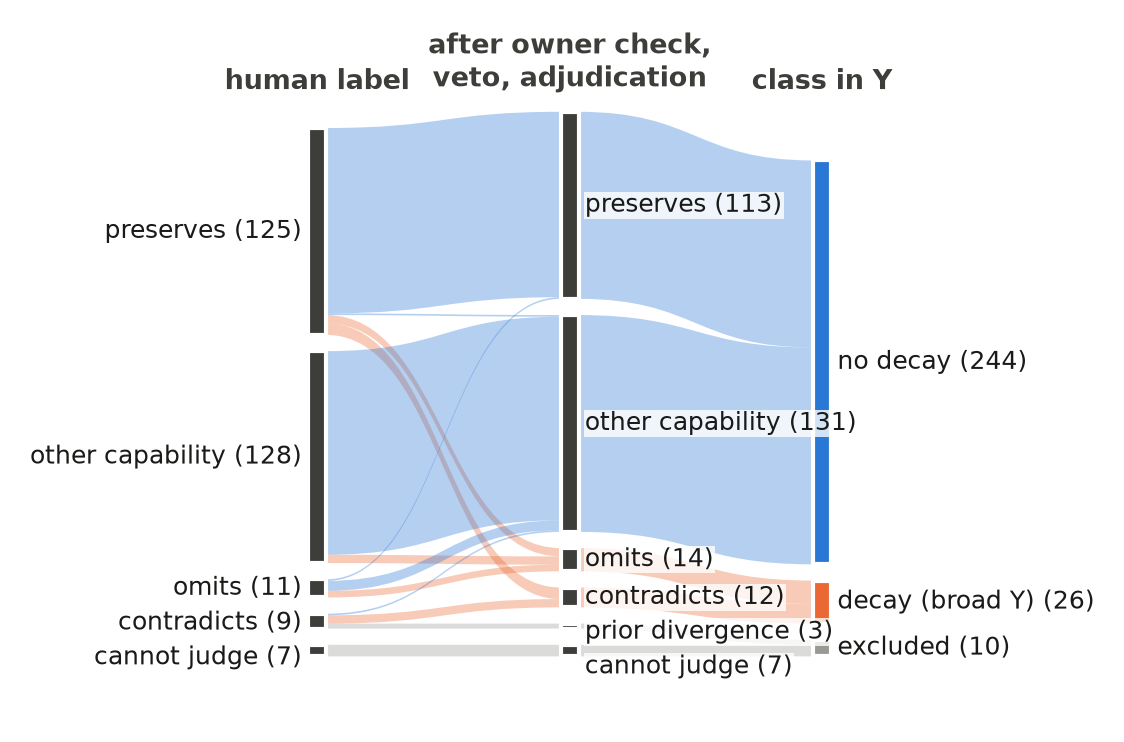

In [11]:
etapa("scripts/analysis/p4_fluxo.py")
display(Image("data/derived/figures/p4_fluxo_completa.png", width=700))

## 10. Sorteio da adjudicação refeito a partir da semente

A ordem cega (A/B) das duas leituras na adjudicação foi sorteada uma vez, antes da adjudicação. `p4_adjudicacao.py
--conferir` refaz a ordem a partir da semente (`adj-20261108`), sem gravar nada, e falha se ela não for idêntica à
usada. O sorteio dos pares da RQ2 já foi conferido na etapa 3.

In [12]:
etapa("scripts/analysis/p4_adjudicacao.py", "--conferir")

ordem cega da adjudicação idêntica à chave (28 pares; semente adj-20261108)

[ok: scripts/analysis/p4_adjudicacao.py --conferir em 0 s]


## 11. As saídas são as mesmas de antes?

Compara a impressão digital de agora com a da seção 0. Toda saída que já existia antes precisa ter o mesmo hash.
No pacote de replicação, algumas saídas (como `universe.parquet`) não vêm prontas e só aparecem depois da execução;
essas são listadas como novas.

In [13]:
depois = impressao(os.path.join(REPRO, "saidas_depois_do_notebook.sha256"))
mudou = sorted(k for k in antes if k in depois and antes[k] != depois[k])
novas, sumiram = sorted(set(depois) - set(antes)), sorted(set(antes) - set(depois))
print(f"comparadas: {len(set(antes) & set(depois))}; iguais: {len(set(antes) & set(depois)) - len(mudou)}; "
      f"novas: {len(novas)} {novas}; ausentes agora: {sumiram}")
assert not mudou and not sumiram, f"saídas diferentes: {mudou}"
print("OK: a execução reproduziu exatamente as saídas existentes")

68 saídas

[ok: scripts/hash_saidas.py data/derived/reproducao/saidas_depois_do_notebook.sha256 em 3 s]
comparadas: 68; iguais: 68; novas: 0 []; ausentes agora: []
OK: a execução reproduziu exatamente as saídas existentes


## 12. Números do paper

Executa `numeros_do_paper.ipynb`, que lê as saídas acima e mostra cada número do paper ao lado do arquivo de origem.
Se `paper/main.tex` existe, ele também confere que cada valor aparece no texto do paper.

In [14]:
etapa("scripts/executar_notebook.py")

144 of 144 values found in paper/main.tex
judgment words, shown with their checked numbers: ['Such PRs are common', 'a similar number of pairs as decay']
uses of 'snapshot' other than the version name (v1.0 (July 2026 snapshot)): 0
numbers and verdicts in the paper without a source: 0
ok: 11 células executadas -> numeros_do_paper.ipynb

[ok: scripts/executar_notebook.py  em 3 s]


## 13. Documento de ponta a ponta

`scripts/gerar_explicacao.py` escreve `docs/EXPLICACAO_E2E.md`: cada etapa da pesquisa, cada métrica com a fórmula e o
racional, e todos os valores, lidos das saídas acima. Nenhum número do documento é digitado.

In [15]:
etapa("scripts/gerar_explicacao.py")

ok: docs/EXPLICACAO_E2E.md

[ok: scripts/gerar_explicacao.py  em 0 s]
